# Word embeddings: from English words to vectors

    **Learning outcomes:** compare one-hot vectors and dense embeddings, train Skip-gram
    vectors using training reviews only, and compute word/sentence similarity.

    One-hot vectors identify words but do not express similarity. Word2Vec learns from
    nearby words: CBOW predicts a center word from context; Skip-gram predicts context
    from a center word. Similar context can make antonyms close, so cosine similarity
    is not a sentiment classifier. Small training subsets give unstable neighbors.

In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "Select the Python 3.12 project kernel."
assert version('paddlepaddle').split("+")[0] == '3.3.1', "Select the locked project environment."
print("Python:", sys.version.split()[0])
print('paddlepaddle' + ":", version('paddlepaddle'))
print("Run mode:", 'Default classroom training parameters')

Python: 3.12.12
paddlepaddle: 3.3.1
Run mode: Default classroom training parameters


In [2]:
from pathlib import Path
import os
import sys

# Find the English course root without relying on a specific working directory.
start = Path.cwd().resolve()
COURSE = next((p for p in [start, *start.parents]
               if (p / "COURSE_ROOT").is_file()), None)
if COURSE is None and (start / "english" / "COURSE_ROOT").is_file():
    COURSE = start / "english"
if COURSE is None:
    raise RuntimeError("Start Jupyter inside the project or the english directory.")
sys.path.insert(0, str(COURSE / "common"))
os.environ.setdefault("HF_HOME", str(COURSE / "data" / "huggingface"))
os.environ.setdefault("TORCH_HOME", str(COURSE / "data" / "torch-cache"))

'E:\\deep-learning-lab\\english\\data\\torch-cache'

In [3]:
FRAMEWORK = "paddle"
EXPERIMENT = "word-embeddings"

import json
import random
import numpy as np
from course_data import load_reviews, tokenize, build_vocab, encode, LABELS

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
SMOKE = os.environ.get("COURSE_SMOKE", "0") == "1"
DATA = COURSE / "03-sentiment-analysis" / "data"
OUTPUT = COURSE / "03-sentiment-analysis" / "outputs" / FRAMEWORK / EXPERIMENT
OUTPUT.mkdir(parents=True, exist_ok=True)
train_rows = load_reviews(DATA, "train", 64 if SMOKE else 4000)
validation_rows = load_reviews(DATA, "validation", 32 if SMOKE else 1000)
test_rows = load_reviews(DATA, "test", 32 if SMOKE else 1000)
print("Split sizes:", len(train_rows), len(validation_rows), len(test_rows))
print("Labels:", LABELS)

Split sizes: 4000 1000 1000
Labels: ['negative', 'positive']


## 1. Train Word2Vec on training reviews

In [4]:
from gensim.models import Word2Vec
sentences = [tokenize(row["text"]) for row in train_rows]
word2vec = Word2Vec(sentences=sentences, vector_size=64, window=5,
                    min_count=1 if SMOKE else 2, sg=1, workers=1,
                    epochs=1 if SMOKE else 5, seed=SEED)
words = word2vec.wv.index_to_key
vectors = word2vec.wv.vectors.copy()
print("Vocabulary size:", len(words), "Vector shape:", vectors.shape)
word2vec.save(str(OUTPUT / "english_word2vec.model"))

Vocabulary size: 21459 Vector shape: (21459, 64)


## 2. Load vectors into the framework's embedding layer

    The row index is the token ID. We copy the learned vectors and freeze them for this
    demonstration. In a downstream classifier you can choose to fine-tune them.

In [5]:
import paddle
embedding = paddle.nn.Embedding(len(words), vectors.shape[1])
embedding.weight.set_value(vectors)
embedding.weight.stop_gradient = True
word_to_id = {word: index for index, word in enumerate(words)}
example_word = "movie" if "movie" in word_to_id else words[0]
vector = embedding(paddle.to_tensor([word_to_id[example_word]], dtype="int64")).numpy()[0]
print(f"Embedding for '{example_word}': shape={vector.shape}")

E:\deep-learning-lab\english\03-sentiment-analysis\paddle\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


PLEASE USE OMP_NUM_THREADS WISELY.


Embedding for 'movie': shape=(64,)


## 3. Explore word and sentence similarity

In [6]:
print("Nearest words:", word2vec.wv.most_similar(example_word, topn=min(5, len(words)-1)))

def sentence_vector(text):
    known = [word2vec.wv[word] for word in tokenize(text) if word in word2vec.wv]
    return np.mean(known, axis=0) if known else np.zeros(64, dtype=np.float32)

def cosine(a, b):
    return float(np.dot(a, b) / max(np.linalg.norm(a) * np.linalg.norm(b), 1e-8))

first = "The movie was enjoyable and the acting was excellent."
second = "I liked the film and its performances."
print("Sentence similarity:", cosine(sentence_vector(first), sentence_vector(second)))
print("Try comparing 'good' and 'not good'; average vectors can lose word order.")

Nearest words: [('film', 0.932219386100769), ('tripe', 0.8607538938522339), ('category', 0.8587620854377747), ('sequel', 0.8573477268218994), ('turkey', 0.8480386734008789)]
Sentence similarity: 0.9381734132766724
Try comparing 'good' and 'not good'; average vectors can lose word order.


## 4. Visualize a projection

    This two-dimensional PCA projection is a lossy view of the embedding space.
    Nearby points on the chart do not prove semantic equivalence.

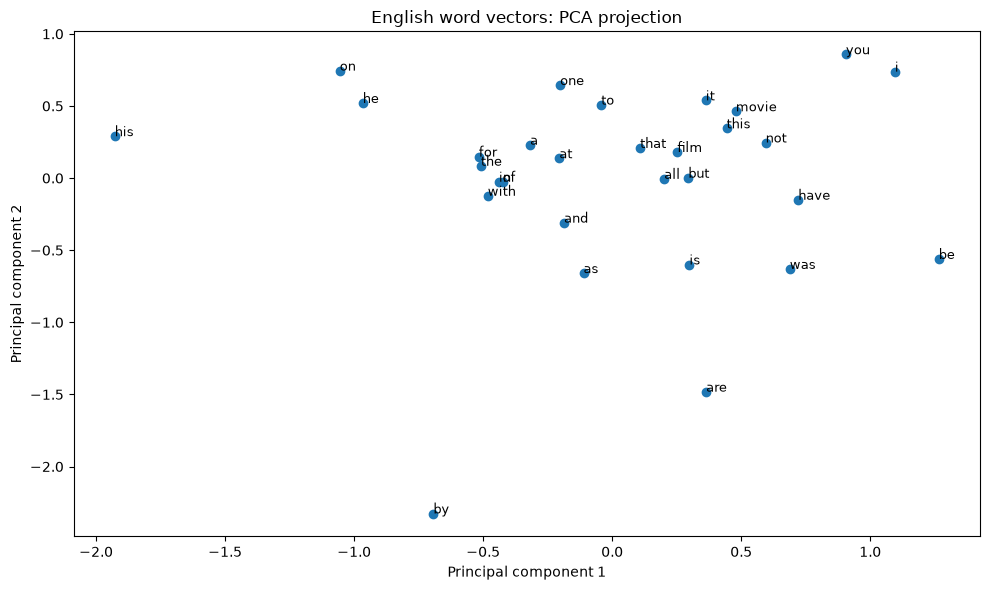

In [7]:
import matplotlib.pyplot as plt
chosen = words[:min(30, len(words))]
matrix = np.stack([word2vec.wv[word] for word in chosen])
centered = matrix - matrix.mean(axis=0)
_, _, axes = np.linalg.svd(centered, full_matrices=False)
points = centered @ axes[:2].T
fig, axis = plt.subplots(figsize=(10, 6))
axis.scatter(points[:, 0], points[:, 1])
for word, (x, y) in zip(chosen, points):
    axis.annotate(word, (x, y), fontsize=9)
axis.set(title="English word vectors: PCA projection", xlabel="Principal component 1",
         ylabel="Principal component 2")
fig.tight_layout()
fig.savefig(OUTPUT / "word_vectors.png")
plt.show()

## Exercises

    Compare CBOW (`sg=0`) and Skip-gram (`sg=1`). Increase training data before interpreting
    neighbors. Test an unknown word and explain why it has no trained vector. Compare
    sentence averaging with an order-sensitive LSTM in the next lesson.